In [27]:
import numpy as np
import matplotlib.pyplot as plt

In [28]:
p_cent = 720                                                # image is 1440 wide
k0 = 950                                                    # +-1 measured value
k_cent = np.array([1070, 1072, 1101, 1131, 1310, 849, 800]) # +-1 measured values of k
lamda_cent = np.array([504.7, 492.1, 471.3, 447.1, 388.8, 667.8, 706.5])
                                                            # corresponding wavelength values from manual

In [29]:
# fit model for wavelength depending on dial position k
def lamda_cent_fit (k, bb, aa):
    return bb * k + aa

1219.9236346050295
-0.6629163292274602
82.68187749066286
0.0780159225553246


<ErrorbarContainer object of 3 artists>

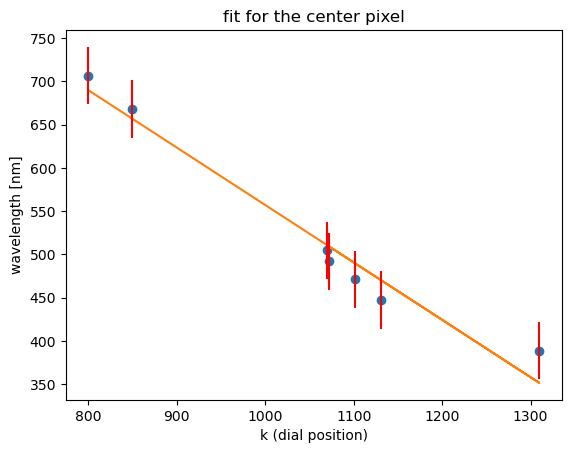

In [30]:
std_k = 50
std_k_cent = np.ones(7) * std_k # uncertenties of k values

from scipy.optimize import curve_fit
# first fit to convert x-error to y-error
popt, pcov = curve_fit(lamda_cent_fit, k_cent, lamda_cent, absolute_sigma=True)

b_prov = popt[0]

# y-error
std_lamda_from_k = np.abs(b_prov * std_k_cent)

# actual fit
popt, pcov = curve_fit(lamda_cent_fit, k_cent, lamda_cent, sigma=std_lamda_from_k, absolute_sigma=True)

# fit parameters a, b for lamda(k) = b*k + a
b = popt[0]
a = popt[1]
print(a)
print(b)

print('========')

std_b = np.sqrt(pcov[0, 0])
std_a = np.sqrt(pcov[1, 1])
print(std_a)
print(std_b)

plt.plot(k_cent, lamda_cent, linestyle='', marker='o')
plt.plot(k_cent, lamda_cent_fit(k_cent, b, a))
plt.xlabel('k (dial position)')
plt.ylabel('wavelength [nm]')
plt.title('fit for the center pixel')
plt.errorbar(k_cent, lamda_cent, std_lamda_from_k, linestyle = '', color='r')

In [31]:
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------

In [32]:
k_fix = 1066                              # +-1 measured value
p_pos = np.array([475, 802, 920])         # pixel position from image
lamda_k = np.array([492.1, 501.5, 504.7]) # values from manual (wavelength)

In [33]:
# fit model including pixel position
def lamda_fit (p, dd):
    return b * k_fix + a + (p - p_cent) / dd

In [34]:
std_p = 20

from scipy.optimize import curve_fit
# first fit to determine y-error from x-error
popt, pcov = curve_fit(lamda_fit, p_pos, lamda_k, absolute_sigma=True)

d_prov = popt[0]
std_lamda_from_p = np.abs(std_p / d_prov)

# actual fit
popt, pcov = curve_fit(lamda_fit, p_pos, lamda_k, sigma=std_lamda_from_p, absolute_sigma=True)
d = popt[0]
print(d)
std_d = np.sqrt(pcov[0, 0])
print(std_d)

42.562165927446685
2.60535034105648


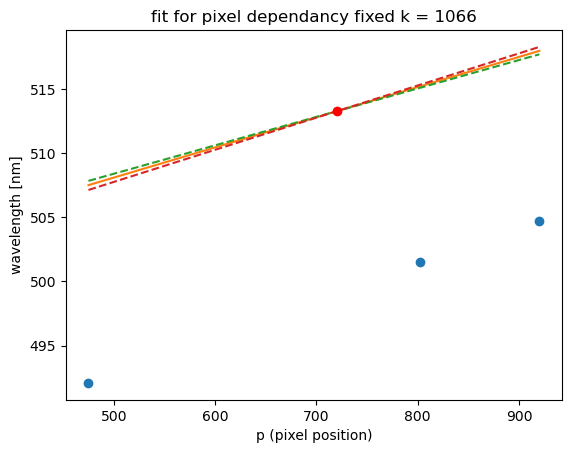

In [42]:
plt.plot(p_pos, lamda_k, linestyle='', marker='o')
offset = 0
plt.plot(p_pos, lamda_fit(p_pos, d) - offset)
plt.plot(p_pos, lamda_fit(p_pos, d + std_d) - offset, linestyle='--')
plt.plot(p_pos, lamda_fit(p_pos, d - std_d) - offset, linestyle='--')

plt.xlabel('p (pixel position)')
plt.ylabel('wavelength [nm]')
plt.title('fit for pixel dependancy fixed k = 1066')

plt.plot(p_cent, lamda_fit(p_cent, d) - offset, marker='o', color='r')

In [15]:
# final fit function
def lamda (p, k):
    return b * k + a + (p - p_cent) / d

In [16]:
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------

In [17]:
# calculation of the lattice constant

In [18]:
lamda_at_center = 667.8                 # wavelength of middle pixel
beta = 15 * 2 * np.pi / 360             # 15° in radians
k_pos = 850                             # +-1 dial position
alpha = (k_pos - 500) * 5.8 / 10**5     # calculates the angle alpha based on manual
print(alpha / (2 * np.pi) * 360)        # prints alpha in degrees

1.1631043241155712


In [19]:
# lattice constant:
d = lamda_at_center / (2 * np.cos(beta) * np.sin(alpha))
print(1 / d)

5.872101698438248e-05


In [20]:
# error prop:
del_alpha = 5.8 / 10**5
std_alpha = np.sqrt((del_alpha * std_k)**2)

del_g = 2 * np.cos(beta) * np.cos(alpha) / lamda_at_center
std_g = np.sqrt((del_g * std_alpha)**2)

print(std_g)

8.387564378306631e-06


In [21]:
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------

In [22]:
measurements = np.array([860, 1080, 1112, 1120])   # +-1 k values
balmer_lamda = lamda(p_cent, measurements)          #literature 656.279, 486.135, 434.0472, 410.1734
print(balmer_lamda)
c = 299792458

print('==============')

# error porp:
del_f_a = 1                           # = 1
del_f_b = measurements                # = k
del_f_d = -(p_cent - p_cent) / d**2   # = -(p - p_cent) / d^2
del_f_p = 1 / d                       # = 1 / d
del_f_k = b                           # = b
std_lamda = np.sqrt((del_f_a * std_a)**2
               + (del_f_b * std_b)**2
               + (del_f_d * std_d)**2
               + (del_f_p * std_p)**2
               + (del_f_k * std_k)**2)

print(std_lamda)

[649.81559147 503.97399904 482.7606765  477.45734587]
[111.51906433 122.6140822  124.3428466  124.77909986]


In [23]:
# calculated values for rydborg frequency
nn = np.array([3, 4, 5, 6])                                   # balmer series
balmer_lamda_m = balmer_lamda / 10**9                         # wavelength in m
ryd_freq = c / balmer_lamda_m * 1 / ((1 / 4) - (1 / nn**2))   # formula from manual
print(ryd_freq)
print(np.mean(ryd_freq))
print(np.mean(ryd_freq) / 10**15)
print('---')
print(np.mean(ryd_freq) / c)

print('=============')

# error prop:
del_ryd_lamda = (-1) * c / (balmer_lamda_m)**2 * 1 / ((1 / 4) - (1 / nn**2))
std_ryd = np.sqrt((del_ryd_lamda * std_lamda / 10**9)**2)
print(std_ryd)

[3.32172039e+15 3.17257063e+15 2.95712390e+15 2.82552164e+15]
3069234138346745.5
3.0692341383467454
---
10237863.08308912
[5.70061960e+14 7.71868861e+14 7.61655249e+14 7.38424174e+14]


In [24]:
# limit of series: f = Rh / 4 | lamda = 4 * c / Rh
print(c / np.mean(ryd_freq) * 4 * 10**9)

print('===========')
# error prop:
del_lamda_lim = (-1) * 4 * c / np.mean(ryd_freq)**2
std_lamda_lim = np.sqrt((del_lamda_lim * np.mean(std_ryd))**2)
print(std_lamda_lim * 10**9)

390.7065339257361
90.44536205858948


In [25]:
# E_photon = h * c / lamda         (h is planks constant)
# E_photon[eV] = E_photon / e      (e is electornic charge)
e = 1.602176634 * 10**(-19)
h = 6.62607015 * 10**(-34)

print(h * np.mean(ryd_freq) / e)

print('=======')
# error prop:
del_E_photon = h / e
sig_E_photon = np.sqrt((del_E_photon * np.mean(std_ryd))**2)
print(sig_E_photon)

12.693332480256567
2.938402489386257
